## **Import Dependencies**

In [62]:
# Let's look at one file carefully first
sample = pd.read_excel("/Users/jaanya/Downloads/PCA_CDB-1001-F-Census.xlsx", header=None)
print(sample.shape)
sample.head(10)

(1541, 95)


,0,1,2,3,4,5,6,7,8,9,...,85,86,87,88,89,90,91,92,93,94
0,State,District,DT Name,CD Block,Town/Village,Ward,EB,Level,Name,TRU,...,MARG_AL_0_3_F,MARG_HH_0_3_P,MARG_HH_0_3_M,MARG_HH_0_3_F,MARG_OT_0_3_P,MARG_OT_0_3_M,MARG_OT_0_3_F,NON_WORK_P,NON_WORK_M,NON_WORK_F
1,10,203,Pashchim Champaran,0001,000000,0000,000000,CD BLOCK,Sidhaw,Total,...,4686,261,116,145,1931,915,1016,159742,74017,85725
2,10,203,Pashchim Champaran,0001,000000,0000,000000,CD BLOCK,Sidhaw,Rural,...,4686,261,116,145,1931,915,1016,159742,74017,85725
3,10,203,Pashchim Champaran,0001,000000,0000,000000,CD BLOCK,Sidhaw,Urban,...,0,0,0,0,0,0,0,0,0,0
4,10,203,Pashchim Champaran,0001,215989,0000,000000,VILLAGE,Kalapani,Rural,...,0,0,0,0,0,0,0,0,0,0
5,10,203,Pashchim Champaran,0001,215990,0000,000000,VILLAGE,Bhaisalotan,Rural,...,27,14,7,7,215,98,117,7020,2915,4105
6,10,203,Pashchim Champaran,0001,215991,0000,000000,VILLAGE,Tharhi,Rural,...,5,1,1,0,12,5,7,1505,641,864
7,10,203,Pashchim Champaran,0001,215992,0000,000000,VILLAGE,Pipra,Rural,...,15,0,0,0,0,0,0,1055,491,564
8,10,203,Pashchim Champaran,0001,215993,0000,000000,VILLAGE,Kotaraha,Rural,...,4,0,0,0,0,0,0,508,221,287
9,10,203,Pashchim Champaran,0001,215994,0000,000000,VILLAGE,Rampurwa,Rural,...,51,5,1,4,0,0,0,2582,1045,1537


In [63]:
import pandas as pd
import glob
import os

folder_path = "/Users/jaanya/Downloads"
files = glob.glob(os.path.join(folder_path, "PCA_CDB*.xlsx"))

all_dfs = []
for f in files:
    df = pd.read_excel(f, header=0)  # row 0 is the header
    # Keep only CD BLOCK level rows (not village rows)
    df = df[df['Level'] == 'CD BLOCK']
    # Keep only Total rows (not Rural/Urban split)
    df = df[df['TRU'] == 'Total']
    all_dfs.append(df)

merged = pd.concat(all_dfs, axis=0, ignore_index=True)
print("Merged shape:", merged.shape)
print("Columns:", merged.columns.tolist())
merged.head()

Merged shape: (534, 95)
Columns: ['State', 'District', 'DT Name', 'CD Block', 'Town/Village', 'Ward', 'EB', 'Level', 'Name', 'TRU', 'No_HH', 'TOT_P', 'TOT_M', 'TOT_F', 'P_06', 'M_06', 'F_06', 'P_SC', 'M_SC', 'F_SC', 'P_ST', 'M_ST', 'F_ST', 'P_LIT', 'M_LIT', 'F_LIT', 'P_ILL', 'M_ILL', 'F_ILL', 'TOT_WORK_P', 'TOT_WORK_M', 'TOT_WORK_F', 'MAINWORK_P', 'MAINWORK_M', 'MAINWORK_F', 'MAIN_CL_P', 'MAIN_CL_M', 'MAIN_CL_F', 'MAIN_AL_P', 'MAIN_AL_M', 'MAIN_AL_F', 'MAIN_HH_P', 'MAIN_HH_M', 'MAIN_HH_F', 'MAIN_OT_P', 'MAIN_OT_M', 'MAIN_OT_F', 'MARGWORK_P', 'MARGWORK_M', 'MARGWORK_F', 'MARG_CL_P', 'MARG_CL_M', 'MARG_CL_F', 'MARG_AL_P', 'MARG_AL_M', 'MARG_AL_F', 'MARG_HH_P', 'MARG_HH_M', 'MARG_HH_F', 'MARG_OT_P', 'MARG_OT_M', 'MARG_OT_F', 'MARGWORK_3_6_P', 'MARGWORK_3_6_M', 'MARGWORK_3_6_F', 'MARG_CL_3_6_P', 'MARG_CL_3_6_M', 'MARG_CL_3_6_F', 'MARG_AL_3_6_P', 'MARG_AL_3_6_M', 'MARG_AL_3_6_F', 'MARG_HH_3_6_P', 'MARG_HH_3_6_M', 'MARG_HH_3_6_F', 'MARG_OT_3_6_P', 'MARG_OT_3_6_M', 'MARG_OT_3_6_F', 'MARGWORK_

,State,District,DT Name,CD Block,Town/Village,Ward,EB,Level,Name,TRU,...,MARG_AL_0_3_F,MARG_HH_0_3_P,MARG_HH_0_3_M,MARG_HH_0_3_F,MARG_OT_0_3_P,MARG_OT_0_3_M,MARG_OT_0_3_F,NON_WORK_P,NON_WORK_M,NON_WORK_F
0,10,213,Madhepura,146,0,0,0,CD BLOCK,Gamharia,Total,...,403,70,12,58,77,34,43,47686,21619,26067
1,10,213,Madhepura,147,0,0,0,CD BLOCK,Singheshwar,Total,...,1892,122,47,75,248,180,68,81852,36617,45235
2,10,213,Madhepura,148,0,0,0,CD BLOCK,Ghailarh,Total,...,1808,116,59,57,90,50,40,51426,24479,26947
3,10,213,Madhepura,149,0,0,0,CD BLOCK,Madhepura,Total,...,2923,398,126,272,316,196,120,114048,52198,61850
4,10,213,Madhepura,150,0,0,0,CD BLOCK,Shankarpur,Total,...,2010,161,76,85,366,85,281,56596,26792,29804


In [64]:
for col in merged.columns.tolist():
    print(col)

State
District
DT Name
CD Block
Town/Village
Ward
EB
Level
Name
TRU
No_HH
TOT_P
TOT_M
TOT_F
P_06
M_06
F_06
P_SC
M_SC
F_SC
P_ST
M_ST
F_ST
P_LIT
M_LIT
F_LIT
P_ILL
M_ILL
F_ILL
TOT_WORK_P
TOT_WORK_M
TOT_WORK_F
MAINWORK_P
MAINWORK_M
MAINWORK_F
MAIN_CL_P
MAIN_CL_M
MAIN_CL_F
MAIN_AL_P
MAIN_AL_M
MAIN_AL_F
MAIN_HH_P
MAIN_HH_M
MAIN_HH_F
MAIN_OT_P
MAIN_OT_M
MAIN_OT_F
MARGWORK_P
MARGWORK_M
MARGWORK_F
MARG_CL_P
MARG_CL_M
MARG_CL_F
MARG_AL_P
MARG_AL_M
MARG_AL_F
MARG_HH_P
MARG_HH_M
MARG_HH_F
MARG_OT_P
MARG_OT_M
MARG_OT_F
MARGWORK_3_6_P
MARGWORK_3_6_M
MARGWORK_3_6_F
MARG_CL_3_6_P
MARG_CL_3_6_M
MARG_CL_3_6_F
MARG_AL_3_6_P
MARG_AL_3_6_M
MARG_AL_3_6_F
MARG_HH_3_6_P
MARG_HH_3_6_M
MARG_HH_3_6_F
MARG_OT_3_6_P
MARG_OT_3_6_M
MARG_OT_3_6_F
MARGWORK_0_3_P
MARGWORK_0_3_M
MARGWORK_0_3_F
MARG_CL_0_3_P
MARG_CL_0_3_M
MARG_CL_0_3_F
MARG_AL_0_3_P
MARG_AL_0_3_M
MARG_AL_0_3_F
MARG_HH_0_3_P
MARG_HH_0_3_M
MARG_HH_0_3_F
MARG_OT_0_3_P
MARG_OT_0_3_M
MARG_OT_0_3_F
NON_WORK_P
NON_WORK_M
NON_WORK_F


In [65]:
merged_renamed = merged.rename(columns={
    'CD Block': 'CD Block_Code',
    'No_HH': 'No of Households',
    'TOT_P': 'Total Population Person',
    'TOT_F': 'Total Population Female',
    'P_06': 'Population in the age group 0-6 Person',
    'P_SC': 'Scheduled Castes population Person',
    'P_ST': 'Scheduled Tribes population Person',
    'F_SC': 'Scheduled Castes population Female',
    'F_ST': 'Scheduled Tribes population Female',
    'P_LIT': 'Literates Population Person',
    'F_LIT': 'Literates Population Female',
    'P_ILL': 'Illiterate Persons',
    'F_ILL': 'Illiterate Female',
    'TOT_WORK_P': 'Total Worker Population Person',
    'TOT_WORK_F': 'Total Worker Population Female',
    'MAIN_CL_P': 'Main Cultivator Population Person',
    'MAIN_AL_P': 'Main Agricultural Labourers Population Person',
    'MARGWORK_P': 'Marginal Worker Population Person',
    'NON_WORK_P': 'Non Working Population Person',
})

# Save to the project folder
merged_renamed.to_csv(
    "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/Merged_Dist_Level_PCA.csv",
    index=False
)
print("Saved successfully!")
print(merged_renamed[['CD Block_Code', 'Name', 'Total Population Person', 'Illiterate Persons']].head())

Saved successfully!
   CD Block_Code         Name  Total Population Person  Illiterate Persons
0            146     Gamharia                    82522               48331
1            147  Singheshwar                   134159               79044
2            148     Ghailarh                    91818               55994
3            149    Madhepura                   191375              112539
4            150   Shankarpur                   106222               59784


In [66]:
import pandas as pd
import os
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler

import warnings
warnings.filterwarnings('ignore')

## **Read the Datasets**

In [67]:
data_gdf = gpd.read_file(r"gadm41_IND_3.shp")

# Filter Bihar only
data_gdf = data_gdf[data_gdf['NAME_1'] == 'Bihar'].copy()

# Rename columns to match what the notebook expects
data_gdf = data_gdf.rename(columns={'NAME_3': 'Name', 'CC_3': 'CD Block_C'})

# Keep only needed columns
data_gdf = data_gdf[['CD Block_C', 'Name', 'geometry']]
data_gdf = data_gdf.reset_index(drop=True)

print(data_gdf.shape)
print(data_gdf.head())

(53, 3)
  CD Block_C        Name                                           geometry
0         NA      Araria  POLYGON ((87.67097 26.11094, 87.66872 26.1079,...
1         NA   Jahanabad  POLYGON ((84.73145 25.05792, 84.73287 25.06813...
2         NA  Aurangabad  POLYGON ((84.44016 25.12959, 84.45296 25.12374...
3         NA       Banka  POLYGON ((86.68749 25.11803, 86.69852 25.11686...
4         NA   Begusarai  POLYGON ((86.30722 25.31689, 86.29183 25.29734...


In [68]:
# Read the entire socio-economic data for Bihar
data_df = pd.read_csv("Merged_Dist_Level_PCA.csv")
required_columns = [
    'CD Block_Code', 'Name', 'Total Population Person', 'No of Households', 'Total Population Female',
    'Population in the age group 0-6 Person', 'Scheduled Castes population Person', 'Scheduled Tribes population Person',
    'Scheduled Castes population Female', 'Scheduled Tribes population Female', 'Illiterate Persons', 'Illiterate Female',
    'Main Cultivator Population Person', 'Main Agricultural Labourers Population Person', 'Marginal Worker Population Person',
    'Non Working Population Person', 'Literates Population Person', 'Literates Population Female', 'Total Worker Population Person',
    'Total Worker Population Female'
]
data_df = data_df[required_columns]
data_df.rename(columns={'CD Block_Code': 'CD Block_C'}, inplace=True)
print(data_df.shape)
data_df.head()

(534, 20)


,CD Block_C,Name,Total Population Person,No of Households,Total Population Female,Population in the age group 0-6 Person,Scheduled Castes population Person,Scheduled Tribes population Person,Scheduled Castes population Female,Scheduled Tribes population Female,Illiterate Persons,Illiterate Female,Main Cultivator Population Person,Main Agricultural Labourers Population Person,Marginal Worker Population Person,Non Working Population Person,Literates Population Person,Literates Population Female,Total Worker Population Person,Total Worker Population Female
0,146,Gamharia,82522,15970,39572,15262,12074,44,5965,13,48331,27048,8415,10875,12894,47686,34191,12524,34836,13505
1,147,Singheshwar,134159,27252,63859,27119,28557,118,13767,52,79044,43476,8872,9748,25658,81852,55115,20383,52307,18624
2,148,Ghailarh,91818,17092,44013,18015,14724,128,7183,55,55994,31634,9369,9490,19847,51426,35824,12379,40392,17066
3,149,Madhepura,191375,38820,91083,38169,37586,94,18124,44,112539,62265,15328,22172,32862,114048,78836,28818,77327,29233
4,150,Shankarpur,106222,22238,51065,19913,24110,171,11603,80,59784,33300,7144,10140,29899,56596,46438,17765,49626,21261


In [69]:
# Aggregate block-level CSV to district level
district_df = merged_renamed.copy()

# Select only numeric columns + district name
numeric_cols = district_df.select_dtypes(include='number').columns.tolist()

# Group by district name and sum
district_df = district_df.groupby('DT Name')[numeric_cols].sum().reset_index()
district_df = district_df.rename(columns={'DT Name': 'District'})

print(district_df.shape)
print(district_df.head())

(38, 92)
     District  State  District  CD Block_Code  Town/Village  Ward  EB  \
0      Araria     90      1881            936             0     0   0   
1       Arwal     50      1200           2660             0     0   0   
2  Aurangabad    110      2585           5159             0     0   0   
3       Banka    110      2475           3718             0     0   0   
4   Begusarai    180      3996           5409             0     0   0   

   No of Households  Total Population Person    TOT_M  ...  MARG_AL_0_3_F  \
0            535361                  2642792  1374254  ...          31042   
1            109769                   648994   336420  ...           5298   
2            358813                  2325945  1206640  ...          21331   
3            367997                  1963450  1029097  ...          36149   
4            488843                  2435094  1284263  ...          13777   

   MARG_HH_0_3_P  MARG_HH_0_3_M  MARG_HH_0_3_F  MARG_OT_0_3_P  MARG_OT_0_3_M  \
0        

In [70]:
# Fix shapefile to district level
data_gdf = gpd.read_file("gadm41_IND_3.shp")
data_gdf = data_gdf[data_gdf['NAME_1'] == 'Bihar'].copy()
data_gdf = data_gdf.rename(columns={'NAME_2': 'District'})
data_gdf = data_gdf[['District', 'geometry']]

# Dissolve multiple rows per district into one polygon
data_gdf = data_gdf.dissolve(by='District').reset_index()
print("Shapefile districts:", data_gdf.shape)
print(data_gdf['District'].tolist())

Shapefile districts: (38, 2)
['Araria', 'Arwal', 'Aurangabad', 'Banka', 'Begusarai', 'Bhagalpur', 'Bhojpur', 'Buxar', 'Darbhanga', 'Gaya', 'Gopalganj', 'Jamui', 'Jehanabad', 'Kaimur', 'Katihar', 'Khagaria', 'Kishanganj', 'Lakhisarai', 'Madhepura', 'Madhubani', 'Munger', 'Muzaffarpur', 'Nalanda', 'Nawada', 'Pashchim Champaran', 'Patna', 'Purba Champaran', 'Purnia', 'Rohtas', 'Saharsa', 'Samastipur', 'Saran', 'Sheikhpura', 'Sheohar', 'Sitamarhi', 'Siwan', 'Supaul', 'Vaishali']


In [73]:
print(type(district_df))
print(district_df.columns.tolist())
print(district_df.head(2))


<class 'pandas.DataFrame'>
['District', 'State', 'District', 'CD Block_Code', 'Town/Village', 'Ward', 'EB', 'No of Households', 'Total Population Person', 'TOT_M', 'Total Population Female', 'Population in the age group 0-6 Person', 'M_06', 'F_06', 'Scheduled Castes population Person', 'M_SC', 'Scheduled Castes population Female', 'Scheduled Tribes population Person', 'M_ST', 'Scheduled Tribes population Female', 'Literates Population Person', 'M_LIT', 'Literates Population Female', 'Illiterate Persons', 'M_ILL', 'Illiterate Female', 'Total Worker Population Person', 'TOT_WORK_M', 'Total Worker Population Female', 'MAINWORK_P', 'MAINWORK_M', 'MAINWORK_F', 'Main Cultivator Population Person', 'MAIN_CL_M', 'MAIN_CL_F', 'Main Agricultural Labourers Population Person', 'MAIN_AL_M', 'MAIN_AL_F', 'MAIN_HH_P', 'MAIN_HH_M', 'MAIN_HH_F', 'MAIN_OT_P', 'MAIN_OT_M', 'MAIN_OT_F', 'Marginal Worker Population Person', 'MARGWORK_M', 'MARGWORK_F', 'MARG_CL_P', 'MARG_CL_M', 'MARG_CL_F', 'MARG_AL_P', 'MA

In [75]:
# Remove duplicate columns first
district_df = district_df.loc[:, ~district_df.columns.duplicated()]

# Now check matches
shapefile_districts = set(data_gdf['District'].str.strip().str.lower())
csv_districts = set(district_df['District'].str.strip().str.lower())

print("Matches:", len(shapefile_districts & csv_districts))
print("In shapefile but not CSV:", shapefile_districts - csv_districts)
print("In CSV but not shapefile:", csv_districts - shapefile_districts)

Matches: 37
In shapefile but not CSV: {'kaimur'}
In CSV but not shapefile: {'kaimur (bhabua)'}


In [76]:
# Fix the one mismatched name
district_df['District'] = district_df['District'].str.replace('Kaimur (Bhabua)', 'Kaimur', regex=False)

# Now merge shapefile and CSV
data_gdf['District_lower'] = data_gdf['District'].str.strip().str.lower()
district_df['District_lower'] = district_df['District'].str.strip().str.lower()

data_gdf = pd.merge(left=data_gdf, right=district_df, on='District_lower', how='left')
data_gdf = data_gdf.drop(columns=['District_lower', 'District_y'])
data_gdf = data_gdf.rename(columns={'District_x': 'District'})

print(data_gdf.shape)
data_gdf.head()

(38, 92)


,District,geometry,State,CD Block_Code,Town/Village,Ward,EB,No of Households,Total Population Person,TOT_M,...,MARG_AL_0_3_F,MARG_HH_0_3_P,MARG_HH_0_3_M,MARG_HH_0_3_F,MARG_OT_0_3_P,MARG_OT_0_3_M,MARG_OT_0_3_F,Non Working Population Person,NON_WORK_M,NON_WORK_F
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",90,936,0,0,0,535361,2642792,1374254,...,31042,3692,810,2882,4770,2014,2756,1624582,707301,917281
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",50,2660,0,0,0,109769,648994,336420,...,5298,594,179,415,1504,1090,414,426968,180124,246844
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",110,5159,0,0,0,358813,2325945,1206640,...,21331,4819,1951,2868,10178,5943,4235,1547008,655063,891945
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",110,3718,0,0,0,367997,1963450,1029097,...,36149,4319,1521,2798,8019,4573,3446,1212035,528407,683628
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",180,5409,0,0,0,488843,2435094,1284263,...,13777,4904,1831,3073,10348,6968,3380,1647667,694506,953161


In [77]:
data_df['Total Population Female'] = (data_df['Total Population Female'] / data_df['Total Population Person']) * 100
data_df['Population in the age group 0-6 Person'] = (data_df['Population in the age group 0-6 Person'] / data_df['Total Population Person']) * 100
data_df['Scheduled Castes population Person'] = (data_df['Scheduled Castes population Person'] / data_df['Total Population Person']) * 100
data_df['Scheduled Tribes population Person'] = (data_df['Scheduled Tribes population Person'] / data_df['Total Population Person']) * 100
data_df['Scheduled Castes population Female'] = (data_df['Scheduled Castes population Female'] / data_df['Total Population Person']) * 100
data_df['Scheduled Tribes population Female'] = (data_df['Scheduled Tribes population Female'] / data_df['Total Population Person']) * 100
data_df['Illiterate Persons'] = (data_df['Illiterate Persons'] / data_df['Total Population Person']) * 100
data_df['Illiterate Female'] = (data_df['Illiterate Female'] / data_df['Total Population Person']) * 100
data_df['Main Cultivator Population Person'] = data_df['Main Cultivator Population Person'] / data_df['Total Worker Population Person']
data_df['Main Agricultural Labourers Population Person'] = data_df['Main Agricultural Labourers Population Person'] / data_df['Total Worker Population Person']
data_df['Marginal Worker Population Person'] = data_df['Marginal Worker Population Person'] / data_df['Total Worker Population Person']
data_df['Non Working Population Person'] = (data_df['Non Working Population Person'] / data_df['Total Population Person']) * 100
data_df['Literates Population Person'] = (data_df['Literates Population Person'] / data_df['Total Population Person']) * 100
data_df['Literates Population Female'] = (data_df['Literates Population Female'] / data_df['Total Population Person']) * 100
data_df['Total Worker Population Person'] = (data_df['Total Worker Population Person'] / data_df['Total Population Person']) * 100
data_df['Total Worker Population Female'] = (data_df['Total Worker Population Female'] / data_df['Total Population Person']) * 100
print(data_df.shape)
data_df.head()


(534, 20)


,CD Block_C,Name,Total Population Person,No of Households,Total Population Female,Population in the age group 0-6 Person,Scheduled Castes population Person,Scheduled Tribes population Person,Scheduled Castes population Female,Scheduled Tribes population Female,Illiterate Persons,Illiterate Female,Main Cultivator Population Person,Main Agricultural Labourers Population Person,Marginal Worker Population Person,Non Working Population Person,Literates Population Person,Literates Population Female,Total Worker Population Person,Total Worker Population Female
0,146,Gamharia,82522,15970,47.953273,18.494462,14.631250,0.053319,7.228375,0.015753,58.567412,32.776714,0.241560,0.312177,0.370134,57.785803,41.432588,15.176559,42.214197,16.365333
1,147,Singheshwar,134159,27252,47.599490,20.214074,21.285937,0.087955,10.261704,0.038760,58.918149,32.406324,0.169614,0.186361,0.490527,61.011188,41.081851,15.193166,38.988812,13.882035
2,148,Ghailarh,91818,17092,47.935045,19.620336,16.036071,0.139406,7.823085,0.059901,60.983685,34.452940,0.231952,0.234948,0.491360,56.008626,39.016315,13.482106,43.991374,18.586769
3,149,Madhepura,191375,38820,47.593991,19.944611,19.639974,0.049118,9.470411,0.022992,58.805487,32.535598,0.198223,0.286730,0.424974,59.593991,41.194513,15.058393,40.406009,15.275245
4,150,Shankarpur,106222,22238,48.073845,18.746587,22.697746,0.160984,10.923349,0.075314,56.282126,31.349438,0.143957,0.204328,0.602487,53.280865,43.717874,16.724407,46.719135,20.015628


In [125]:
# Filter the NaN rows - district level version
data_gdf_nan = data_gdf[data_gdf.isna().any(axis=1)].iloc[:, :2]
data_gdf = data_gdf.dropna()
data_gdf_nan = gpd.sjoin_nearest(left_df=data_gdf_nan, right_df=data_gdf.drop(columns=['District']), how='left')
data_gdf_nan = data_gdf_nan.drop_duplicates(subset=['District'])[data_gdf.columns]
data_gdf = pd.concat((data_gdf, data_gdf_nan), axis=0)
print(data_gdf.shape)
data_gdf.head()

(38, 92)


,District,geometry,State,CD Block_Code,Town/Village,Ward,EB,No of Households,Total Population Person,TOT_M,...,MARG_AL_0_3_F,MARG_HH_0_3_P,MARG_HH_0_3_M,MARG_HH_0_3_F,MARG_OT_0_3_P,MARG_OT_0_3_M,MARG_OT_0_3_F,Non Working Population Person,NON_WORK_M,NON_WORK_F
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",90,936,0,0,0,535361,2642792,1374254,...,31042,3692,810,2882,4770,2014,2756,1624582,707301,917281
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",50,2660,0,0,0,109769,648994,336420,...,5298,594,179,415,1504,1090,414,426968,180124,246844
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",110,5159,0,0,0,358813,2325945,1206640,...,21331,4819,1951,2868,10178,5943,4235,1547008,655063,891945
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",110,3718,0,0,0,367997,1963450,1029097,...,36149,4319,1521,2798,8019,4573,3446,1212035,528407,683628
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",180,5409,0,0,0,488843,2435094,1284263,...,13777,4904,1831,3073,10348,6968,3380,1647667,694506,953161


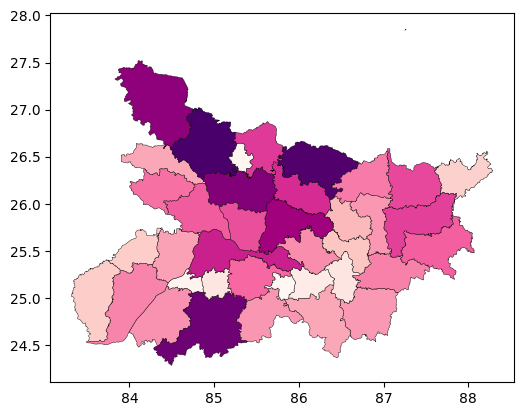

In [126]:
data_gdf.plot(column='Total Worker Population Person', edgecolor='k', linewidth=0.3, cmap='RdPu');

## **Pearson Correlation Analysis**

In [127]:
def get_highly_correlated_columns(df, threshold=0.9, method='pearson'):
    """
    Identify column names in a DataFrame that are highly correlated above a given threshold.

    Parameters:
    - df (pd.DataFrame): The input DataFrame with numeric columns.
    - threshold (float): Correlation threshold (0 < threshold <= 1). Default is 0.9.
    - method (str): Correlation method: 'pearson', 'kendall', or 'spearman'. Default is 'pearson'.

    Returns:
    - correlated_columns (set): Set of column names that are involved in at least one high correlation pair.
    """

    if not 0 < threshold <= 1:
        raise ValueError("Threshold must be between 0 and 1.")

    # Compute the correlation matrix
    corr_matrix = df.corr(method=method)

    # Create a set to store correlated column names
    correlated_columns = set()

    # Check upper triangle only
    for i in range(len(corr_matrix.columns)):
        for j in range(i + 1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) >= threshold:
                correlated_columns.add(corr_matrix.columns[i])
                correlated_columns.add(corr_matrix.columns[j])

    return correlated_columns

In [128]:
# Divide the data into inputs and output
inputs = [
    'Total Population Person',
    'Total Population Female',
    'No of Households',
    'Population in the age group 0-6 Person',
    'Scheduled Castes population Person',
    'Scheduled Castes population Female',
    'Scheduled Tribes population Person',
    'Scheduled Tribes population Female',
    'Illiterate Persons',
    'Illiterate Female',
    'Main Cultivator Population Person',
    'Main Agricultural Labourers Population Person',
    'Marginal Worker Population Person',
    'Non Working Population Person'
]

outputs = [
    'Literates Population Person',
    'Literates Population Female',
    'Total Worker Population Person',
    'Total Worker Population Female'
]

data_df_inputs = data_df[['CD Block_C', 'Name'] + inputs]
data_df_outputs = data_df[['CD Block_C', 'Name'] + outputs]
print(data_df_inputs.shape, data_df_outputs.shape)

(534, 16) (534, 6)


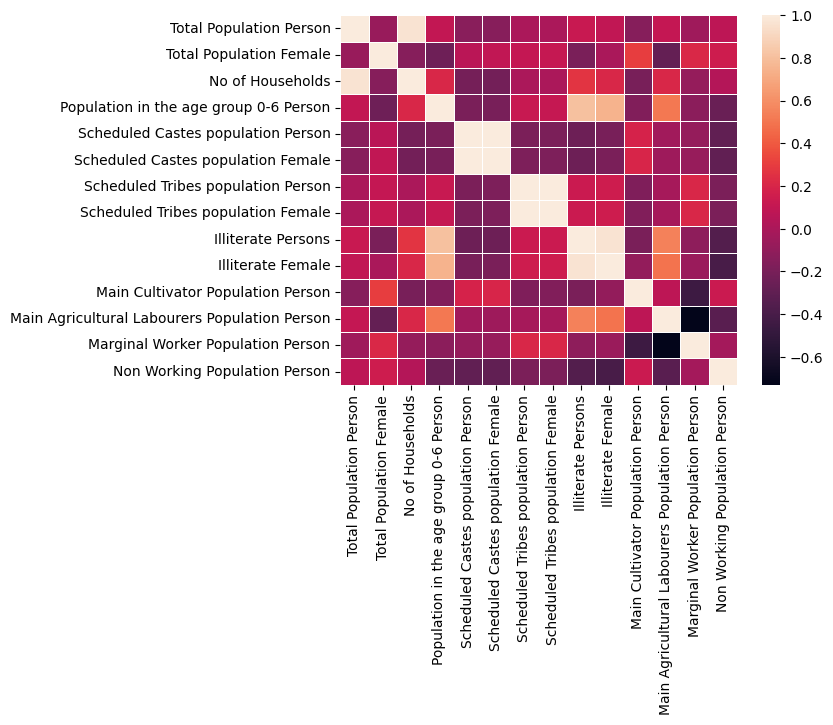

In [129]:
sns.heatmap(data_df_inputs.iloc[:, 2:].corr(), edgecolor='k', linewidth=0.5);

In [130]:
# Find the highly correlated columns
correlated_cols_input = get_highly_correlated_columns(data_df_inputs.iloc[:, 2:], threshold=0.9)
correlated_cols_output = get_highly_correlated_columns(data_df_outputs.iloc[:, 2:], threshold=0.9)
print('Length of correlated input columns:', len(correlated_cols_input))
print('Length of correlated output columns:', len(correlated_cols_output))

Length of correlated input columns: 8
Length of correlated output columns: 4


In [131]:
# Split the correlated and uncorrelated features
uncorrelated_cols = set(data_df_inputs.columns[2:]).difference(correlated_cols_input)
data_df_inputs_corr = data_df_inputs[['CD Block_C', 'Name'] + list(correlated_cols_input)]
data_df_inputs_non_corr = data_df_inputs[['CD Block_C', 'Name'] + list(uncorrelated_cols)]

print(data_df_inputs_corr.shape, data_df_inputs_non_corr.shape)

(534, 10) (534, 8)


## **Apply PCA on Correlated Variables**

In [132]:
def pca_until_variance(df, variance_threshold=0.90):
    """
    Perform PCA on a DataFrame and return the transformed features
    needed to reach the specified cumulative explained variance.

    Parameters:
    - df (pd.DataFrame): DataFrame with numeric features.
    - variance_threshold (float): Desired cumulative explained variance (0 < threshold <= 1).

    Returns:
    - pca_features (pd.DataFrame): Transformed PCA features up to desired variance.
    - n_components (int): Number of components used.
    """
    # Standardize the data
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df)

    # Fit PCA
    pca = PCA()
    pca.fit(scaled_data)

    # Calculate cumulative explained variance
    cum_var = pca.explained_variance_ratio_.cumsum()

    # Find number of components to reach the threshold
    n_components = (cum_var < variance_threshold).sum() + 1

    # Apply PCA with the selected number of components
    pca_final = PCA(n_components=n_components)
    pca_features = pca_final.fit_transform(scaled_data)

    # Return as DataFrame
    pca_df = pd.DataFrame(pca_features, columns=[f'PC{i+1}' for i in range(n_components)])

    return pca_df, n_components

def plot_explained_variance(df):
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df)

    pca = PCA()
    pca.fit(scaled_data)

    explained_var = pca.explained_variance_ratio_
    cum_var = explained_var.cumsum()

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(explained_var) + 1), cum_var, marker='o', linestyle='--')
    plt.title('Cumulative Explained Variance by PCA Components')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.grid(True)
    plt.axhline(y=0.90, color='r', linestyle='--', label='90% threshold')
    plt.legend()
    plt.tight_layout()
    plt.show()

In [133]:
# Apply PCA on correlated dataset
data_df_inputs_corr_pca, n_components = pca_until_variance(data_df_inputs_corr.iloc[:, 2:], variance_threshold=0.90)
print(data_df_inputs_corr_pca.shape)
data_df_inputs_corr_pca.head()

(534, 4)


,PC1,PC2,PC3,PC4
0,-0.343920,0.591357,1.995769,-1.274892
1,0.072518,-0.132226,2.050042,0.248963
2,-0.596179,0.459143,2.565310,-0.945169
3,-0.605372,-0.854687,1.531214,0.524348
4,0.740951,0.255206,1.908415,0.203606


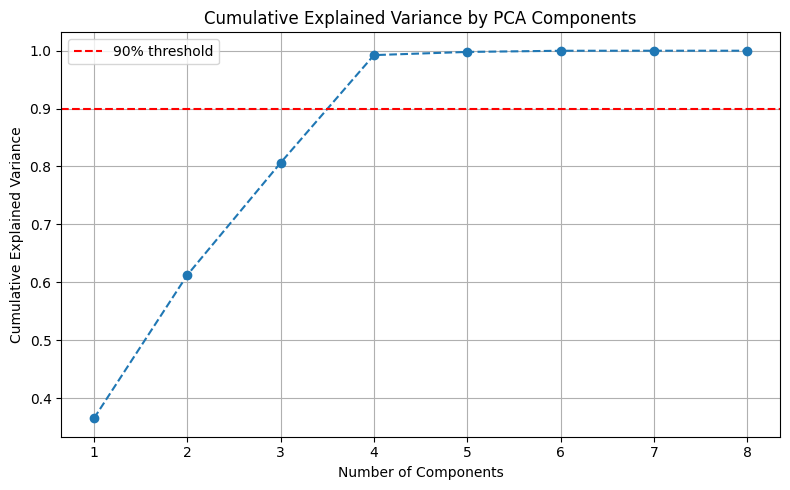

In [134]:
plot_explained_variance(data_df_inputs_corr.iloc[:, 2:])

In [135]:
# Apply Min-Max Normalization
scaler = MinMaxScaler()
data_df_inputs_corr_pca_scaled = scaler.fit_transform(data_df_inputs_corr_pca)
data_df_inputs_corr_pca_scaled = pd.DataFrame(data_df_inputs_corr_pca_scaled, columns=data_df_inputs_corr_pca.columns)
print(data_df_inputs_corr_pca_scaled.shape)
data_df_inputs_corr_pca_scaled.head()

(534, 4)


,PC1,PC2,PC3,PC4
0,0.648987,0.219614,0.702683,0.174524
1,0.685206,0.180762,0.710588,0.322079
2,0.627047,0.212515,0.785636,0.206451
3,0.626247,0.141971,0.635021,0.348744
4,0.743341,0.201565,0.689960,0.317687


In [136]:
# Merge the dataframes
scaler = MinMaxScaler()
data_df_inputs_non_corr_scaled = scaler.fit_transform(data_df_inputs_non_corr.iloc[:, 2:])
data_df_inputs_non_corr_scaled = pd.DataFrame(data_df_inputs_non_corr_scaled, columns=data_df_inputs_non_corr.columns[2:])

final_inputs_df = pd.concat((data_df_inputs.iloc[:, :2], data_df_inputs_non_corr_scaled, data_df_inputs_corr_pca_scaled), axis=1)
print(final_inputs_df.shape)
final_inputs_df.head()

(534, 12)


,CD Block_C,Name,Marginal Worker Population Person,Non Working Population Person,Main Cultivator Population Person,Total Population Female,Main Agricultural Labourers Population Person,Population in the age group 0-6 Person,PC1,PC2,PC3,PC4
0,146,Gamharia,0.371225,0.239970,0.697225,0.256114,0.516184,0.381842,0.648987,0.219614,0.702683,0.174524
1,147,Singheshwar,0.581418,0.364103,0.430978,0.200600,0.247786,0.602842,0.685206,0.180762,0.710588,0.322079
2,148,Ghailarh,0.582872,0.171572,0.661667,0.253254,0.351433,0.526537,0.627047,0.212515,0.785636,0.206451
3,149,Madhepura,0.466970,0.309560,0.536850,0.199737,0.461899,0.568212,0.626247,0.141971,0.635021,0.348744
4,150,Shankarpur,0.776888,0.066591,0.336030,0.275034,0.286115,0.414245,0.743341,0.201565,0.689960,0.317687


In [137]:
scaler = MinMaxScaler()
data_df_outputs_scaled = scaler.fit_transform(data_df_outputs.iloc[:, 2:])
data_df_outputs_scaled = pd.DataFrame(data_df_outputs_scaled, columns=data_df_outputs.columns[2:])
data_df_outputs_scaled = pd.concat((data_df_outputs.iloc[:, :2], data_df_outputs_scaled), axis=1)
print(data_df_outputs_scaled.shape)
data_df_outputs_scaled.head()

(534, 6)


,CD Block_C,Name,Literates Population Person,Literates Population Female,Total Worker Population Person,Total Worker Population Female
0,146,Gamharia,0.300309,0.307582,0.760030,0.744015
1,147,Singheshwar,0.289090,0.308651,0.635897,0.607990
2,148,Ghailarh,0.223018,0.198540,0.828428,0.865697
3,149,Madhepura,0.292694,0.299978,0.690440,0.684304
4,150,Shankarpur,0.373411,0.407190,0.933409,0.943965


## **CCR DEA Model Implementation**

In [138]:
# Install Pulp
!pip install pulp
from pulp import LpProblem, LpMaximize, LpVariable, lpSum, LpStatus, value

zsh:1: command not found: pip


In [139]:
def ccr_dea(inputs, outputs):
    n_dmus, n_inputs = inputs.shape
    _, n_outputs = outputs.shape
    efficiencies = []

    for dmu in range(n_dmus):
        # LP model
        model = LpProblem(f"CCR_DEA_DM{dmu}", LpMaximize)

        # Define variables
        u = [LpVariable(f"u_{r}", lowBound=0) for r in range(n_outputs)]
        v = [LpVariable(f"v_{i}", lowBound=0) for i in range(n_inputs)]

        # Objective: Maximize efficiency of DMU dmu
        model += lpSum([u[r] * outputs[dmu, r] for r in range(n_outputs)])

        # Constraint: Denominator of objective is fixed at 1
        model += lpSum([v[i] * inputs[dmu, i] for i in range(n_inputs)]) == 1

        # Constraints: efficiency ≤ 1 for all DMUs
        for j in range(n_dmus):
            model += lpSum([u[r] * outputs[j, r] for r in range(n_outputs)]) <= \
                     lpSum([v[i] * inputs[j, i] for i in range(n_inputs)])

        # Solve the model
        model.solve()

        # Get efficiency score
        if LpStatus[model.status] == 'Optimal':
            eff = value(model.objective)
        else:
            eff = None
        efficiencies.append(eff)

    return efficiencies


In [140]:
efficiency_score = ccr_dea(final_inputs_df.iloc[:, 2:].values, data_df_outputs_scaled.iloc[:, 2:].values)

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pulp/apis/../solverdir/cbc/osx/i64/cbc /var/folders/b8/qm9hs2lx1gl13sfll_1q35r00000gp/T/99daf3e7e1e448a186419c4ddd475465-pulp.mps -max -timeMode elapsed -solve -printingOptions all -solution /var/folders/b8/qm9hs2lx1gl13sfll_1q35r00000gp/T/99daf3e7e1e448a186419c4ddd475465-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 540 COLUMNS
At line 8017 RHS
At line 8553 BOUNDS
At line 8554 ENDATA
Problem MODEL has 535 rows, 14 columns and 7472 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Presolve 535 (0) rows, 14 (0) columns and 7472 (0) elements
0  Obj -0 Primal inf 3.4017314 (1) Dual inf 3.4499418 (4)
0  Obj -0 Primal inf 3.4017314 (1) Dual inf 1.7324109e+11 (14)
24  Obj 0.89328664
Optimal - objective value 0.89328664
Optimal objective 0.89328664

In [141]:
efficiency_score_gdf = data_gdf[['District', 'geometry']].copy()
efficiency_score_gdf['Technical_Efficiency'] = efficiency_score[:len(efficiency_score_gdf)]
efficiency_score_gdf = gpd.GeoDataFrame(efficiency_score_gdf)
print(efficiency_score_gdf.shape)
efficiency_score_gdf.head()

(38, 3)


,District,geometry,Technical_Efficiency
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",0.893287
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",0.828288
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",1.000000
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",0.893342
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",1.000000


In [142]:
print(final_inputs_df.columns[:5].tolist())

['CD Block_C', 'Name', 'Marginal Worker Population Person', 'Non Working Population Person', 'Main Cultivator Population Person']


In [143]:
# Fix geometry before plotting
efficiency_score_gdf = efficiency_score_gdf[efficiency_score_gdf.geometry.is_valid]
efficiency_score_gdf = efficiency_score_gdf[~efficiency_score_gdf.geometry.is_empty]
efficiency_score_gdf = efficiency_score_gdf.dropna(subset=['geometry'])
efficiency_score_gdf = efficiency_score_gdf.to_crs(epsg=4326)

print(efficiency_score_gdf.shape)

(38, 3)


In [144]:
print(efficiency_score_gdf.crs)
print(efficiency_score_gdf.shape)
print(efficiency_score_gdf['Technical_Efficiency'].describe())
print(efficiency_score_gdf.total_bounds)

EPSG:4326
(38, 3)
count    38.000000
mean      0.884336
std       0.118543
min       0.612873
25%       0.823607
50%       0.910223
75%       0.997966
max       1.000000
Name: Technical_Efficiency, dtype: float64
[83.31607056 24.28704071 88.29191589 27.85071333]


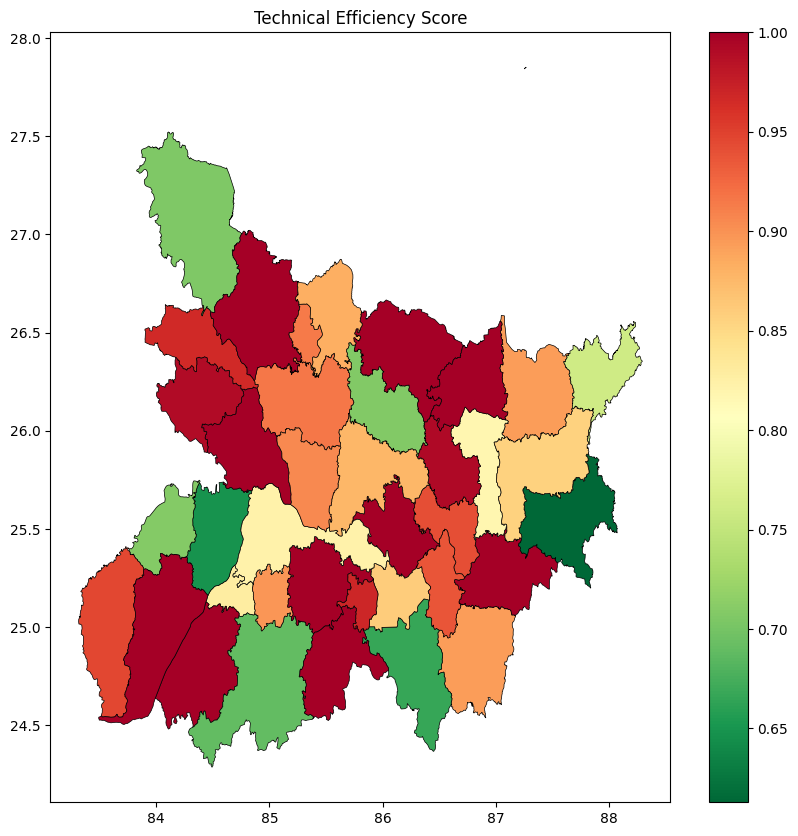

In [145]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
efficiency_score_gdf.plot(
    column='Technical_Efficiency',
    linewidth=0.5,
    edgecolor='k',
    legend=True,
    cmap='RdYlGn_r',
    ax=ax,
    aspect=None  # ← this fixes the error
)
ax.set_title('Technical Efficiency Score')
plt.show()

## **Read the Susceptibility Values**

In [147]:
model_path = "/Users/jaanya/Downloads/Flood-Risk-Mapping-Bihar--main-2/"

RF_susceptibility_df = pd.read_csv(model_path + 'Bihar_Vulnerability_With_RF.csv')
RF_susceptibility_df = RF_susceptibility_df[['District', 'RF_Susceptibility']].rename(columns={'RF_Susceptibility': 'RF_Susceptibility'})

XGB_susceptibility_df = pd.read_csv(model_path + 'Bihar_Vulnerability_With_XGB.csv')
XGB_susceptibility_df = XGB_susceptibility_df[['District', 'XGB_Susceptibility']].rename(columns={'XGB_Susceptibility': 'XGB_Susceptibility'})

final_susceptibility_df = pd.merge(left=RF_susceptibility_df, right=XGB_susceptibility_df, on='District', how='inner')
print(final_susceptibility_df.shape)
final_susceptibility_df.head()

(38, 3)


,District,RF_Susceptibility,XGB_Susceptibility
0,Araria,0.462178,0.432093
1,Arwal,0.865500,0.950000
2,Aurangabad,0.712396,0.711721
3,Banka,0.619061,0.566175
4,Begusarai,0.309213,0.350340


## **Calculate the Flood Risk Scores**

In [148]:
vulnerability_gdf = pd.merge(left=efficiency_score_gdf, right=final_susceptibility_df, on='District', how='left')
vulnerability_gdf['SEV'] = 1 - vulnerability_gdf['Technical_Efficiency']
vulnerability_gdf['RF_Flood_Risk'] = vulnerability_gdf['RF_Susceptibility'] * vulnerability_gdf['SEV']
vulnerability_gdf['XGB_Flood_Risk'] = vulnerability_gdf['XGB_Susceptibility'] * vulnerability_gdf['SEV']
vulnerability_gdf = gpd.GeoDataFrame(vulnerability_gdf, geometry='geometry')
print(vulnerability_gdf.shape)
vulnerability_gdf[['District', 'Technical_Efficiency', 'SEV', 'RF_Flood_Risk', 'XGB_Flood_Risk']].head()

(38, 8)


,District,Technical_Efficiency,SEV,RF_Flood_Risk,XGB_Flood_Risk
0,Araria,0.893287,1.067134e-01,4.932058e-02,4.611007e-02
1,Arwal,0.828288,1.717120e-01,1.486167e-01,1.631264e-01
2,Aurangabad,1.000000,2.847027e-08,2.028210e-08,2.026288e-08
3,Banka,0.893342,1.066581e-01,6.602789e-02,6.038721e-02
4,Begusarai,1.000000,-6.312519e-10,-1.951913e-10,-2.211530e-10


In [149]:
vulnerability_gdf['RF_Flood_Risk_Index'] = vulnerability_gdf['RF_Flood_Risk']
vulnerability_gdf['XGB_Flood_Risk_Index'] = vulnerability_gdf['XGB_Flood_Risk']
print(vulnerability_gdf[['District', 'RF_Flood_Risk_Index', 'XGB_Flood_Risk_Index']].head())

     District  RF_Flood_Risk_Index  XGB_Flood_Risk_Index
0      Araria         4.932058e-02          4.611007e-02
1       Arwal         1.486167e-01          1.631264e-01
2  Aurangabad         2.028210e-08          2.026288e-08
3       Banka         6.602789e-02          6.038721e-02
4   Begusarai        -1.951913e-10         -2.211530e-10


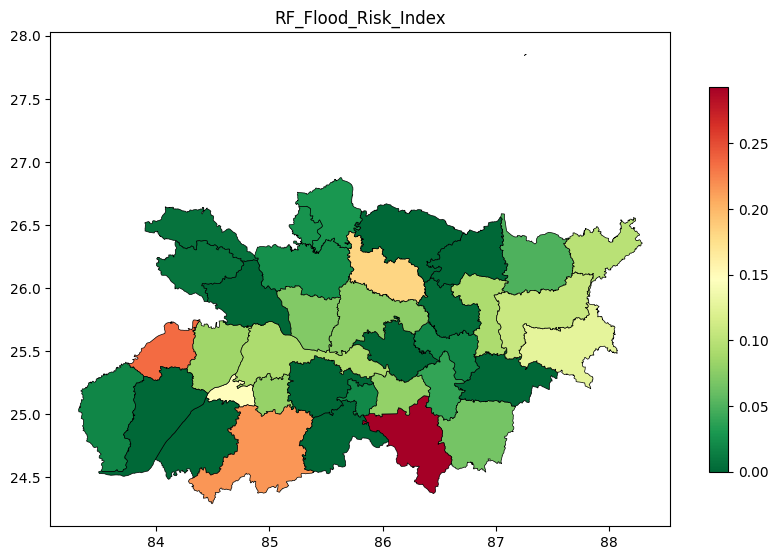

In [150]:
vulnerability_gdf.plot(column='RF_Flood_Risk_Index', linewidth=0.5, edgecolor='k', legend=True, legend_kwds={'shrink': 0.5},
                       cmap='RdYlGn_r', figsize=(10, 10))
plt.title('RF_Flood_Risk_Index');

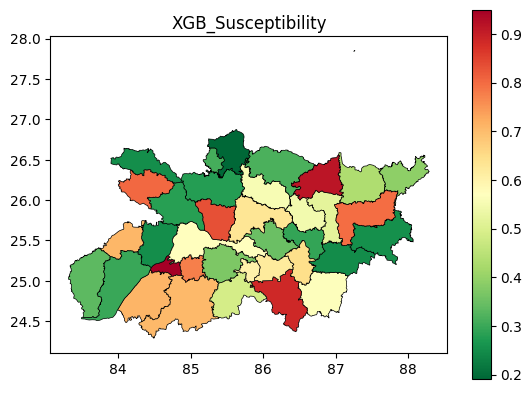

In [151]:
vulnerability_gdf.plot(column='XGB_Susceptibility', linewidth=0.5, edgecolor='k', legend=True,
                       cmap='RdYlGn_r')
plt.title('XGB_Susceptibility');

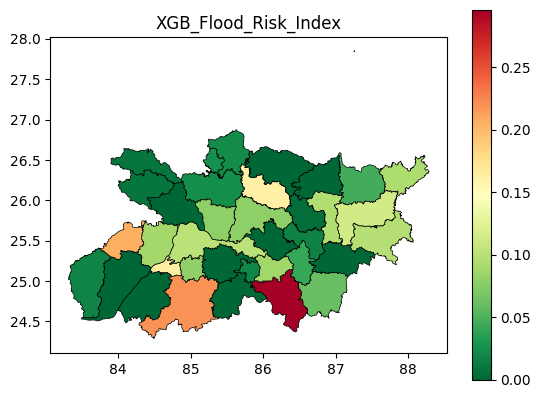

In [152]:
vulnerability_gdf.plot(column='XGB_Flood_Risk_Index', linewidth=0.5, edgecolor='k', legend=True,
                       cmap='RdYlGn_r')
plt.title('XGB_Flood_Risk_Index');

In [153]:
# vulnerability_gdf.to_file("/content/drive/MyDrive/Harish's Dissertation/Bihar Project Work/Vulnerability_Datasets/Risk_Score/Risk_Score.shp")

In [154]:
data_gdf_nan

,District,geometry,State,CD Block_Code,Town/Village,Ward,EB,No of Households,Total Population Person,TOT_M,...,MARG_AL_0_3_F,MARG_HH_0_3_P,MARG_HH_0_3_M,MARG_HH_0_3_F,MARG_OT_0_3_P,MARG_OT_0_3_M,MARG_OT_0_3_F,Non Working Population Person,NON_WORK_M,NON_WORK_F


In [158]:
# Filter the NaN rows - district level version
data_gdf = vulnerability_gdf.dropna()
print(data_gdf.shape)
data_gdf.head()

(36, 10)


,District,geometry,Technical_Efficiency,RF_Susceptibility,XGB_Susceptibility,SEV,RF_Flood_Risk,XGB_Flood_Risk,RF_Flood_Risk_Index,XGB_Flood_Risk_Index
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",0.893287,0.462178,0.432093,1.067134e-01,4.932058e-02,4.611007e-02,4.932058e-02,4.611007e-02
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",0.828288,0.865500,0.950000,1.717120e-01,1.486167e-01,1.631264e-01,1.486167e-01,1.631264e-01
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",1.000000,0.712396,0.711721,2.847027e-08,2.028210e-08,2.026288e-08,2.028210e-08,2.026288e-08
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",0.893342,0.619061,0.566175,1.066581e-01,6.602789e-02,6.038721e-02,6.602789e-02,6.038721e-02
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",1.000000,0.309213,0.350340,-6.312519e-10,-1.951913e-10,-2.211530e-10,-1.951913e-10,-2.211530e-10


In [159]:
data_gdf.to_file('vulnerability_output.gpkg')

In [160]:
print(data_gdf.columns.tolist())

['District', 'geometry', 'Technical_Efficiency', 'RF_Susceptibility', 'XGB_Susceptibility', 'SEV', 'RF_Flood_Risk', 'XGB_Flood_Risk', 'RF_Flood_Risk_Index', 'XGB_Flood_Risk_Index']


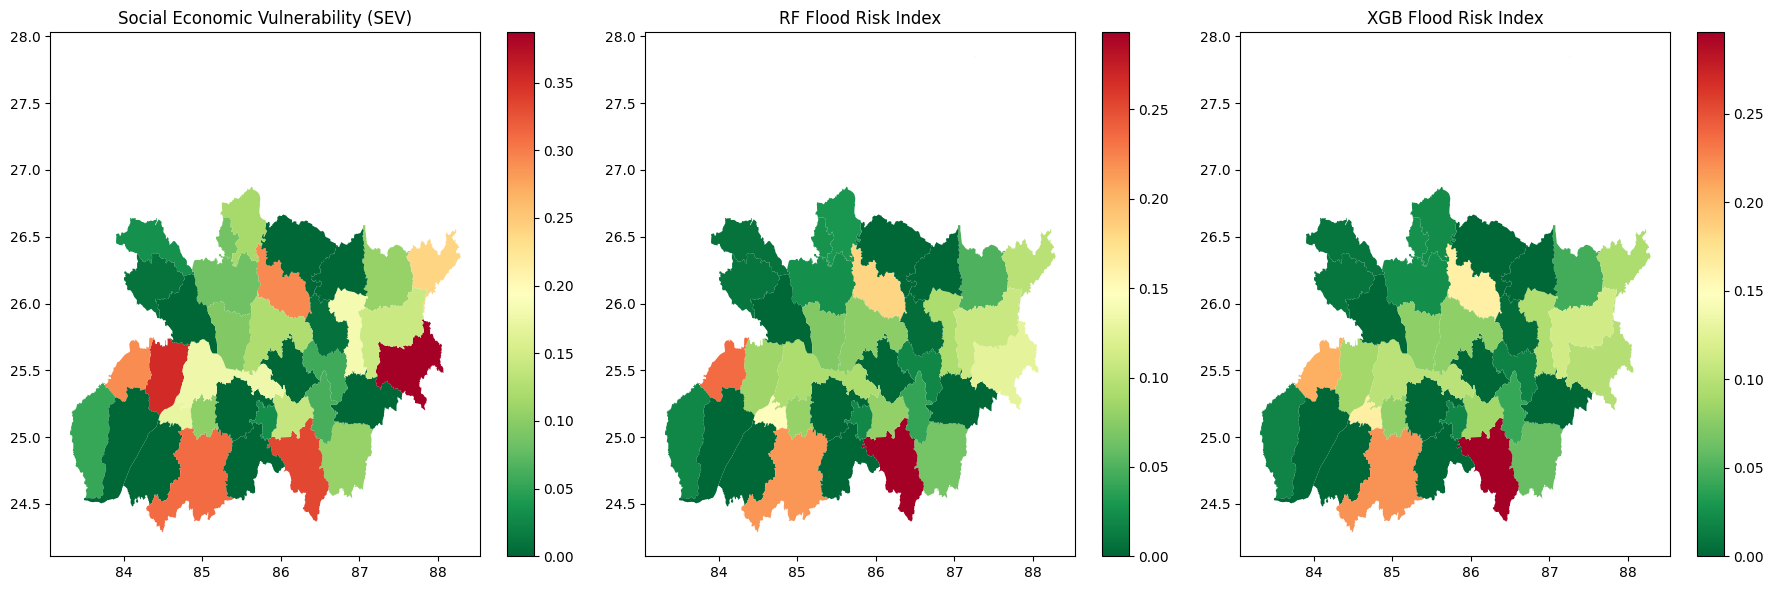

Maps saved!


In [161]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

data_gdf.plot(column='SEV', cmap='RdYlGn_r', legend=True, ax=axes[0], aspect=None)
axes[0].set_title('Social Economic Vulnerability (SEV)')

data_gdf.plot(column='RF_Flood_Risk_Index', cmap='RdYlGn_r', legend=True, ax=axes[1], aspect=None)
axes[1].set_title('RF Flood Risk Index')

data_gdf.plot(column='XGB_Flood_Risk_Index', cmap='RdYlGn_r', legend=True, ax=axes[2], aspect=None)
axes[2].set_title('XGB Flood Risk Index')

plt.tight_layout()
plt.savefig('flood_risk_maps.png', dpi=150, bbox_inches='tight')
plt.show()
print("Maps saved!")

In [171]:

risk_map = risk_csv.copy()
risk_map.head()

,District,geometry,Technical_Efficiency,RF_Susceptibility,XGB_Susceptibility,RF_Flood_Risk_Index,XGB_Flood_Risk_Index,SEV
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",0.893287,0.462178,0.432093,4.932058e-02,4.611007e-02,1.067134e-01
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",0.828288,0.865500,0.950000,1.486167e-01,1.631264e-01,1.717120e-01
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",1.000000,0.712396,0.711721,2.028210e-08,2.026288e-08,2.847027e-08
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",0.893342,0.619061,0.566175,6.602789e-02,6.038721e-02,1.066581e-01
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",1.000000,0.309213,0.350340,-1.951913e-10,-2.211530e-10,-6.312519e-10


In [164]:
# Use our existing vulnerability data as the risk map
risk_csv = data_gdf[['District', 'geometry', 'Technical_Efficiency', 'RF_Susceptibility', 
                      'XGB_Susceptibility', 'RF_Flood_Risk_Index', 'XGB_Flood_Risk_Index', 'SEV']].copy()
risk_csv.head()

,District,geometry,Technical_Efficiency,RF_Susceptibility,XGB_Susceptibility,RF_Flood_Risk_Index,XGB_Flood_Risk_Index,SEV
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",0.893287,0.462178,0.432093,4.932058e-02,4.611007e-02,1.067134e-01
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",0.828288,0.865500,0.950000,1.486167e-01,1.631264e-01,1.717120e-01
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",1.000000,0.712396,0.711721,2.028210e-08,2.026288e-08,2.847027e-08
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",0.893342,0.619061,0.566175,6.602789e-02,6.038721e-02,1.066581e-01
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",1.000000,0.309213,0.350340,-1.951913e-10,-2.211530e-10,-6.312519e-10


In [167]:
# Use risk_csv directly as risk_map_updated
risk_map_updated = risk_csv.copy()
print(risk_map_updated.isnull().sum())
risk_map_updated.head()

District                0
geometry                0
Technical_Efficiency    0
RF_Susceptibility       0
XGB_Susceptibility      0
RF_Flood_Risk_Index     0
XGB_Flood_Risk_Index    0
SEV                     0
dtype: int64


,District,geometry,Technical_Efficiency,RF_Susceptibility,XGB_Susceptibility,RF_Flood_Risk_Index,XGB_Flood_Risk_Index,SEV
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",0.893287,0.462178,0.432093,4.932058e-02,4.611007e-02,1.067134e-01
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",0.828288,0.865500,0.950000,1.486167e-01,1.631264e-01,1.717120e-01
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",1.000000,0.712396,0.711721,2.028210e-08,2.026288e-08,2.847027e-08
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",0.893342,0.619061,0.566175,6.602789e-02,6.038721e-02,1.066581e-01
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",1.000000,0.309213,0.350340,-1.951913e-10,-2.211530e-10,-6.312519e-10


In [169]:
risk_map_updated

,District,geometry,Technical_Efficiency,RF_Susceptibility,XGB_Susceptibility,RF_Flood_Risk_Index,XGB_Flood_Risk_Index,SEV
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",0.893287,0.462178,0.432093,4.932058e-02,4.611007e-02,1.067134e-01
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",0.828288,0.865500,0.950000,1.486167e-01,1.631264e-01,1.717120e-01
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",1.000000,0.712396,0.711721,2.028210e-08,2.026288e-08,2.847027e-08
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",0.893342,0.619061,0.566175,6.602789e-02,6.038721e-02,1.066581e-01
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",1.000000,0.309213,0.350340,-1.951913e-10,-2.211530e-10,-6.312519e-10
5,Bhagalpur,"POLYGON ((87.16461 25.05885, 87.16379 25.06273...",1.000000,0.309196,0.248154,-6.672054e-09,-5.354842e-09,-2.157871e-08
6,Bhojpur,"POLYGON ((84.69715 25.31647, 84.68082 25.30941...",0.647693,0.240659,0.251102,8.478564e-02,8.846484e-02,3.523068e-01
7,Buxar,"POLYGON ((84.38117 25.73425, 84.36733 25.71893...",0.708729,0.806323,0.708340,2.348587e-01,2.063189e-01,2.912711e-01
8,Darbhanga,"POLYGON ((86.04698 26.20131, 86.04606 26.21125...",0.707665,0.620781,0.554371,1.814758e-01,1.620621e-01,2.923349e-01
9,Gaya,"POLYGON ((84.73145 25.05792, 84.74802 25.05378...",0.689962,0.695651,0.705494,2.156785e-01,2.187302e-01,3.100385e-01


In [168]:
# Identify numeric columns (excluding 'CD Block_C' and 'CD_Block_C' if they exist and are identifiers)
numeric_cols_updated = risk_map_updated.select_dtypes(include=np.number).columns.tolist()

# Exclude identifier columns if they are present in numeric_cols_updated
identifier_cols = ['CD Block_C', 'CD_Block_C']
for col in identifier_cols:
    if col in numeric_cols_updated:
        numeric_cols_updated.remove(col)

# Fill NaN values in numeric columns with the mean of each column
for col in numeric_cols_updated:
    risk_map_updated[col] = risk_map_updated[col].fillna(risk_map_updated[col].mean())

print(risk_map_updated.isnull().sum())
risk_map_updated.head()

District                0
geometry                0
Technical_Efficiency    0
RF_Susceptibility       0
XGB_Susceptibility      0
RF_Flood_Risk_Index     0
XGB_Flood_Risk_Index    0
SEV                     0
dtype: int64


,District,geometry,Technical_Efficiency,RF_Susceptibility,XGB_Susceptibility,RF_Flood_Risk_Index,XGB_Flood_Risk_Index,SEV
0,Araria,"POLYGON ((87.67097 26.11094, 87.66872 26.1079,...",0.893287,0.462178,0.432093,4.932058e-02,4.611007e-02,1.067134e-01
1,Arwal,"POLYGON ((84.73145 25.05792, 84.73287 25.06813...",0.828288,0.865500,0.950000,1.486167e-01,1.631264e-01,1.717120e-01
2,Aurangabad,"POLYGON ((84.44016 25.12959, 84.45296 25.12374...",1.000000,0.712396,0.711721,2.028210e-08,2.026288e-08,2.847027e-08
3,Banka,"POLYGON ((86.68749 25.11803, 86.69852 25.11686...",0.893342,0.619061,0.566175,6.602789e-02,6.038721e-02,1.066581e-01
4,Begusarai,"POLYGON ((86.30722 25.31689, 86.29183 25.29734...",1.000000,0.309213,0.350340,-1.951913e-10,-2.211530e-10,-6.312519e-10


In [ ]:
# risk_map_updated.to_file('/content/drive/MyDrive/Bihar Project Work/Vul_data/Risk_Map/Updated_Risk_Map.shp')